# 05 - Selectivity benchmark against experiment

Notebook 03 found that docking does not reproduce trimethoprim's selectivity. One
compound is an anecdote. This tests the protocol against **experimental $K_i$ values**
for every compound ChEMBL has measured in *both* enzymes.

### Why experiment and not FEP

FEP is itself validated against experimental binding data. With measured $K_i$ in hand,
routing through FEP to judge docking would put a second model between us and the
answer. Experiment is the ground truth; FEP is a (very good) way of estimating it when
you have none.

### Why $K_i$ and not IC$_{50}$

For a competitive inhibitor, Cheng-Prusoff relates the two:

$$
K_i \;=\; \frac{\mathrm{IC}_{50}}{1 + [S]/K_m}
$$

IC$_{50}$ depends on the substrate concentration the assay happened to use; $K_i$ does
not. ChEMBL rarely records $[S]$, so the correction cannot be applied afterwards.
Pooling IC$_{50}$ across labs would compare quantities that are not the same thing, so
only $K_i$ is used here.

Kernel: **Python (dhfr)**. Run notebooks 02 and 03 first.

In [1]:
import json
import sys

sys.path.insert(0, "../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import dhfr_lib as D

R_KCAL, T_K = 1.987e-3, 310.0
RT = R_KCAL * T_K
LN10_RT = RT * np.log(10)     # kcal/mol per log10 unit

print(f"RT               = {RT:.3f} kcal/mol")
print(f"RT ln(10)        = {LN10_RT:.3f} kcal/mol per log10 unit")

RT               = 0.616 kcal/mol
RT ln(10)        = 1.418 kcal/mol per log10 unit


## The experimental set

Binding free energy from the measured constant:

$$
\Delta G = RT \ln K_i \;=\; -RT\ln(10)\;\mathrm{p}K_i
$$

and the experimental selectivity, defined so that **more negative means more
bacterial-selective**, matching the sign convention of a Vina score:

$$
\Delta\Delta G_{\mathrm{exp}} \;=\; \Delta G^{\text{ecoli}} - \Delta G^{\text{human}}
\;=\; -RT\ln(10)\left(\mathrm{p}K_i^{\text{ecoli}} - \mathrm{p}K_i^{\text{human}}\right)
$$

In [2]:
raw = json.loads((D.RAW / "chembl_dhfr_ki.json").read_text())

frames = []
for enzyme, rows in raw.items():
    f = pd.DataFrame(rows)
    f["enzyme"] = enzyme
    frames.append(f)
acts = pd.concat(frames, ignore_index=True)

clean = acts[
    (acts.standard_relation == "=")          # exact, not ">" censored
    & (acts.standard_units == "nM")
    & acts.standard_value.notna()
    & acts.canonical_smiles.notna()
].copy()
clean["standard_value"] = clean.standard_value.astype(float)
clean = clean[clean.standard_value > 0]
clean["pKi"] = -np.log10(clean.standard_value * 1e-9)

print(f"records fetched : {len(acts)}")
print(f"after cleaning  : {len(clean)}  {clean.groupby('enzyme').size().to_dict()}")

# Median across papers reporting the same compound/enzyme pair.
agg = (clean.groupby(["molecule_chembl_id", "enzyme"])
       .agg(pKi=("pKi", "median"), n_refs=("pKi", "size"),
            smiles=("canonical_smiles", "first"))
       .reset_index())

wide = agg.pivot(index="molecule_chembl_id", columns="enzyme", values="pKi")
bench = wide.dropna().join(agg.groupby("molecule_chembl_id").smiles.first())
bench["sel_log"] = bench.ecoli - bench.human
bench["ddG_exp"] = -LN10_RT * bench.sel_log
bench["dG_exp_ecoli"] = -LN10_RT * bench.ecoli
bench["dG_exp_human"] = -LN10_RT * bench.human

print(f"\nmeasured in BOTH enzymes: {len(bench)} compounds")
print(f"selectivity spans {bench.sel_log.min():+.2f} to {bench.sel_log.max():+.2f} "
      f"log units ({10 ** (bench.sel_log.max() - bench.sel_log.min()):.0f}-fold range)")
bench[["ecoli", "human", "sel_log", "ddG_exp"]].round(2).sort_values("sel_log")

records fetched : 778
after cleaning  : 755  {'ecoli': 266, 'human': 489}

measured in BOTH enzymes: 25 compounds
selectivity spans -4.23 to +3.07 log units (19922298-fold range)


,ecoli,human,sel_log,ddG_exp
molecule_chembl_id,,,,
CHEMBL34259,6.48,10.71,-4.23,6.00
CHEMBL6948,6.40,6.89,-0.49,0.69
CHEMBL747,5.99,6.39,-0.40,0.56
CHEMBL6742,5.51,5.78,-0.27,0.38
CHEMBL7130,6.76,7.01,-0.26,0.36
CHEMBL31235,6.25,6.48,-0.23,0.33
CHEMBL285209,6.39,6.43,-0.04,0.06
CHEMBL274031,6.99,6.94,0.05,-0.07
CHEMBL31946,6.82,6.74,0.08,-0.11


## Dock every compound into both receptors

Same recipe as notebook 02, same boxes, same exhaustiveness. Nothing is tuned per
compound, that would be fitting the benchmark.

In [3]:
boxes = {k: np.array(v) for k, v in json.loads((D.PREP / "boxes.json").read_text()).items()}

ENZYME_RECEPTOR = {"ecoli": "1rx2", "human": "1u72"}
EXHAUSTIVENESS = 32

results, failures = [], []

for cid, row in bench.iterrows():
    try:
        lig = D.prepare_ligand(row.smiles, f"bench_{cid}")
    except Exception as exc:
        failures.append({"compound": cid, "stage": "prepare", "error": str(exc)[:90]})
        continue

    scores = {}
    for enzyme, rec_key in ENZYME_RECEPTOR.items():
        try:
            res = D.run_vina(D.PREP / f"{rec_key}_receptor.pdbqt", lig,
                             boxes[rec_key], f"bench_{cid}_{enzyme}",
                             seed=42, exhaustiveness=EXHAUSTIVENESS, num_modes=5)
            scores[enzyme] = res.top_score
        except Exception as exc:
            failures.append({"compound": cid, "stage": enzyme, "error": str(exc)[:90]})

    if len(scores) == 2:
        results.append({"compound": cid, "score_ecoli": scores["ecoli"],
                        "score_human": scores["human"]})

docked = pd.DataFrame(results).set_index("compound")
print(f"docked successfully : {len(docked)}/{len(bench)}")
if failures:
    print(f"failures            : {len(failures)}")
    display(pd.DataFrame(failures))

docked successfully : 25/25


In [4]:
df = bench.join(docked, how="inner")
df["ddG_calc"] = df.score_ecoli - df.score_human

# Heavy-atom count: Vina scores scale with ligand size, which is the usual
# confounder when comparing raw scores across a diverse set.
from rdkit import Chem

df["heavy_atoms"] = [Chem.MolFromSmiles(s).GetNumAtoms() for s in df.smiles]
df["le_ecoli"] = -df.score_ecoli / df.heavy_atoms      # ligand efficiency

print(f"benchmark set: {len(df)} compounds")
df[["ecoli", "human", "sel_log", "ddG_exp", "score_ecoli", "score_human",
    "ddG_calc", "heavy_atoms"]].round(2).sort_values("sel_log")

benchmark set: 25 compounds


,ecoli,human,sel_log,ddG_exp,score_ecoli,score_human,ddG_calc,heavy_atoms
molecule_chembl_id,,,,,,,,
CHEMBL34259,6.48,10.71,-4.23,6.00,-8.24,-10.11,1.87,33
CHEMBL6948,6.40,6.89,-0.49,0.69,-8.63,-10.00,1.37,20
CHEMBL747,5.99,6.39,-0.40,0.56,-6.86,-8.85,2.00,17
CHEMBL6742,5.51,5.78,-0.27,0.38,-6.96,-8.36,1.40,16
CHEMBL7130,6.76,7.01,-0.26,0.36,-7.29,-8.88,1.59,17
CHEMBL31235,6.25,6.48,-0.23,0.33,-7.58,-8.63,1.05,24
CHEMBL285209,6.39,6.43,-0.04,0.06,-7.63,-8.67,1.04,23
CHEMBL274031,6.99,6.94,0.05,-0.07,-8.89,-10.01,1.12,23
CHEMBL31946,6.82,6.74,0.08,-0.11,-7.93,-8.24,0.31,20


## Test 1 - can docking rank potency *within* one enzyme?

The easier question, and the one docking is actually designed for.

In [5]:
within = []
for enzyme in ("ecoli", "human"):
    exp = df[f"dG_exp_{enzyme}"]
    calc = df[f"score_{enzyme}"]
    rho, p_rho = stats.spearmanr(calc, exp)
    r, p_r = stats.pearsonr(calc, exp)
    within.append({
        "enzyme": enzyme, "n": len(df),
        "spearman_rho": round(rho, 3), "p_spearman": f"{p_rho:.3f}",
        "pearson_r": round(r, 3),
        "rmse_kcal": round(float(np.sqrt(np.mean((calc - exp) ** 2))), 2),
        "mean_signed_err": round(float(np.mean(calc - exp)), 2),
    })

within_df = pd.DataFrame(within)
within_df

,enzyme,n,spearman_rho,p_spearman,pearson_r,rmse_kcal,mean_signed_err
0,ecoli,25,0.541,0.005,0.595,2.84,2.54
1,human,25,0.113,0.590,0.101,1.72,-0.14


## Test 2 - can docking predict *selectivity*?

The question that matters here, and the hard one: it requires the score to be
calibrated **across two different proteins**.

In [6]:
rho_sel, p_sel = stats.spearmanr(df.ddG_calc, df.ddG_exp)
r_sel, p_r_sel = stats.pearsonr(df.ddG_calc, df.ddG_exp)
rmse_sel = float(np.sqrt(np.mean((df.ddG_calc - df.ddG_exp) ** 2)))

# Does it at least get the DIRECTION right?
both_nonzero = df[df.sel_log.abs() > 0.5]
agree = (np.sign(both_nonzero.ddG_calc) == np.sign(both_nonzero.ddG_exp)).sum()

print(f"selectivity, n = {len(df)}")
print(f"  Spearman rho      : {rho_sel:+.3f}  (p = {p_sel:.3f})")
print(f"  Pearson r         : {r_sel:+.3f}  (p = {p_r_sel:.3f})")
print(f"  RMSE              : {rmse_sel:.2f} kcal/mol")
print(f"  experimental range: {df.ddG_exp.min():+.2f} to {df.ddG_exp.max():+.2f} kcal/mol")
print(f"  predicted range   : {df.ddG_calc.min():+.2f} to {df.ddG_calc.max():+.2f} kcal/mol")
print(f"  dynamic range     : predicted spans "
      f"{(df.ddG_calc.max() - df.ddG_calc.min()) / (df.ddG_exp.max() - df.ddG_exp.min()):.1%} "
      "of experimental")
print()
print(f"  direction correct : {agree}/{len(both_nonzero)} compounds with >0.5 log selectivity")
print(f"  (coin flip would give ~{len(both_nonzero) / 2:.0f})")

selectivity, n = 25
  Spearman rho      : -0.208  (p = 0.317)
  Pearson r         : -0.161  (p = 0.443)
  RMSE              : 3.54 kcal/mol
  experimental range: -4.36 to +6.00 kcal/mol
  predicted range   : +0.31 to +2.74 kcal/mol
  dynamic range     : predicted spans 23.4% of experimental

  direction correct : 1/14 compounds with >0.5 log selectivity
  (coin flip would give ~7)


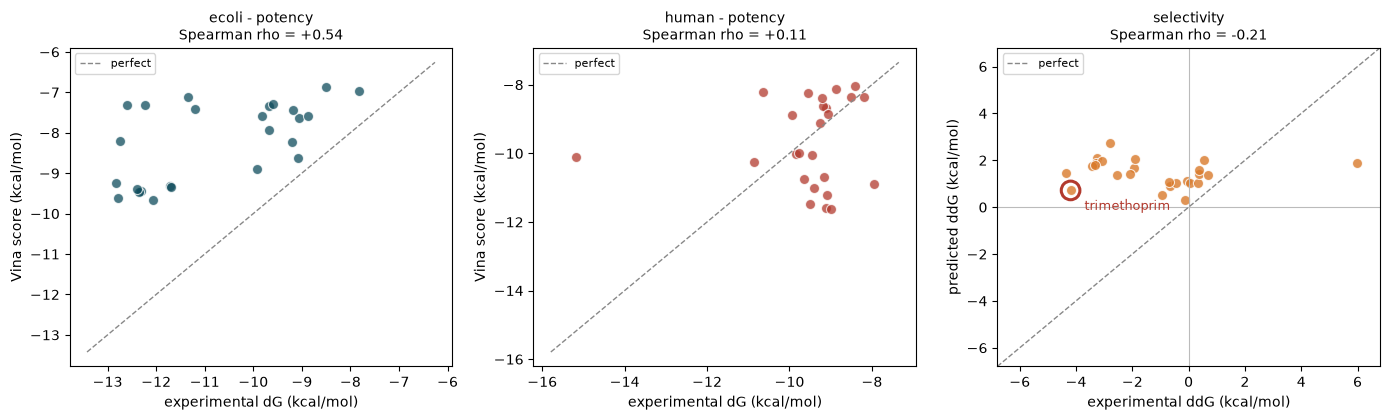

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))

for ax, enzyme, colour in zip(axes[:2], ("ecoli", "human"), ("#0f4c5c", "#b23a2e")):
    exp, calc = df[f"dG_exp_{enzyme}"], df[f"score_{enzyme}"]
    ax.scatter(exp, calc, s=52, color=colour, alpha=0.75, edgecolor="white", lw=0.8)
    lims = [min(exp.min(), calc.min()) - 0.6, max(exp.max(), calc.max()) + 0.6]
    ax.plot(lims, lims, ls="--", lw=1, color="#888", label="perfect")
    rho = within_df.loc[within_df.enzyme == enzyme, "spearman_rho"].iloc[0]
    ax.set_title(f"{enzyme} - potency\nSpearman rho = {rho:+.2f}", fontsize=10)
    ax.set_xlabel("experimental dG (kcal/mol)")
    ax.set_ylabel("Vina score (kcal/mol)")
    ax.legend(fontsize=8)

ax = axes[2]
ax.axhline(0, lw=0.8, color="#bbb")
ax.axvline(0, lw=0.8, color="#bbb")
ax.scatter(df.ddG_exp, df.ddG_calc, s=52, color="#d97a2b",
           alpha=0.8, edgecolor="white", lw=0.8)

tmp_id = "CHEMBL22"
if tmp_id in df.index:
    ax.scatter(df.loc[tmp_id, "ddG_exp"], df.loc[tmp_id, "ddG_calc"],
               s=180, facecolor="none", edgecolor="#b23a2e", lw=2.2, zorder=5)
    ax.annotate("trimethoprim", (df.loc[tmp_id, "ddG_exp"], df.loc[tmp_id, "ddG_calc"]),
                textcoords="offset points", xytext=(10, -14), fontsize=9, color="#b23a2e")

lim = max(abs(df.ddG_exp).max(), abs(df.ddG_calc).max()) + 0.8
ax.plot([-lim, lim], [-lim, lim], ls="--", lw=1, color="#888", label="perfect")
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("experimental ddG (kcal/mol)")
ax.set_ylabel("predicted ddG (kcal/mol)")
ax.set_title(f"selectivity\nSpearman rho = {rho_sel:+.2f}", fontsize=10)
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(D.FIGURES / "fig6_selectivity_benchmark.png", dpi=300, bbox_inches="tight")
plt.show()

## Test 3 - the double-difference

If the failure is a constant per-protein offset, referencing every compound to one
shared ligand should cancel it:

$$
\Delta\Delta G^{\mathrm{ref}}_{X} \;=\; \bigl(\Delta G_X^{\text{ecoli}} - \Delta G_{\mathrm{ref}}^{\text{ecoli}}\bigr) - \bigl(\Delta G_X^{\text{human}} - \Delta G_{\mathrm{ref}}^{\text{human}}\bigr)
$$

This is the cheap analogue of a thermodynamic cycle. If it does not help, the problem
is not a constant offset.

In [8]:
ref = df.sel_log.abs().idxmin()        # most non-selective compound as reference
print(f"reference compound: {ref} (experimental selectivity "
      f"{df.loc[ref, 'sel_log']:+.2f} log units)")

dd_calc = df.ddG_calc - df.loc[ref, "ddG_calc"]
dd_exp = df.ddG_exp - df.loc[ref, "ddG_exp"]
rho_dd, p_dd = stats.spearmanr(dd_calc.drop(ref), dd_exp.drop(ref))
rmse_dd = float(np.sqrt(np.mean((dd_calc.drop(ref) - dd_exp.drop(ref)) ** 2)))

print(f"\n{'':22s} {'Spearman':>10s} {'RMSE':>10s}")
print(f"{'raw score difference':22s} {rho_sel:>+10.3f} {rmse_sel:>9.2f}")
print(f"{'double difference':22s} {rho_dd:>+10.3f} {rmse_dd:>9.2f}")
print()
print("A double difference shifts every point by the same constant, so Spearman is")
print("unchanged by construction - only the RMSE can move. It corrects an offset,")
print("never a lack of correlation.")

reference compound: CHEMBL285209 (experimental selectivity -0.04 log units)

                         Spearman       RMSE
raw score difference       -0.208      3.54
double difference          -0.200      2.93

A double difference shifts every point by the same constant, so Spearman is
unchanged by construction - only the RMSE can move. It corrects an offset,
never a lack of correlation.


## Verdict

In [9]:
summary = pd.DataFrame([
    {"test": "potency ranking, E. coli", "n": len(df),
     "spearman": within_df.loc[0, "spearman_rho"],
     "rmse_kcal": within_df.loc[0, "rmse_kcal"]},
    {"test": "potency ranking, human", "n": len(df),
     "spearman": within_df.loc[1, "spearman_rho"],
     "rmse_kcal": within_df.loc[1, "rmse_kcal"]},
    {"test": "selectivity (cross-protein)", "n": len(df),
     "spearman": round(rho_sel, 3), "rmse_kcal": round(rmse_sel, 2)},
    {"test": "selectivity, double difference", "n": len(df) - 1,
     "spearman": round(rho_dd, 3), "rmse_kcal": round(rmse_dd, 2)},
])
summary.to_csv(D.RESULTS / "selectivity_benchmark.csv", index=False)
df.to_csv(D.RESULTS / "benchmark_compounds.csv")

print(summary.to_string(index=False))
print()

# Published reference points, for scale. Cited, not reproduced here.
print("For scale, from the published literature:")
print("  relative FEP, congeneric series, one protein : ~1.0-1.5 kcal/mol RMSE")
print("  docking, absolute affinity                   : ~2-3 kcal/mol, weak rank order")
print(f"  this protocol, potency within one enzyme     : "
      f"{within_df.rmse_kcal.mean():.1f} kcal/mol RMSE")
print(f"  this protocol, cross-protein selectivity     : {rmse_sel:.1f} kcal/mol RMSE")
print()

if abs(rho_sel) < 0.3 or p_sel > 0.05:
    print("VERDICT: no usable correlation with experimental selectivity.")
    print("The trimethoprim result in notebook 03 was not bad luck - this protocol")
    print("cannot rank cross-protein selectivity for this target at all.")
else:
    print(f"VERDICT: a real but limited correlation (rho = {rho_sel:+.2f}).")
    print("Usable for coarse triage, not for a selectivity claim about any one compound.")

print()
print("What this does and does not establish: it measures THIS protocol on THIS")
print("target pair with 25 compounds from heterogeneous assays. It is not a general")
print("statement about docking, and the small n means the confidence interval on")
print("every correlation above is wide.")

                          test  n  spearman  rmse_kcal
      potency ranking, E. coli 25     0.541       2.84
        potency ranking, human 25     0.113       1.72
   selectivity (cross-protein) 25    -0.208       3.54
selectivity, double difference 24    -0.200       2.93

For scale, from the published literature:
  relative FEP, congeneric series, one protein : ~1.0-1.5 kcal/mol RMSE
  docking, absolute affinity                   : ~2-3 kcal/mol, weak rank order
  this protocol, potency within one enzyme     : 2.3 kcal/mol RMSE
  this protocol, cross-protein selectivity     : 3.5 kcal/mol RMSE

VERDICT: no usable correlation with experimental selectivity.
The trimethoprim result in notebook 03 was not bad luck - this protocol
cannot rank cross-protein selectivity for this target at all.

What this does and does not establish: it measures THIS protocol on THIS
target pair with 25 compounds from heterogeneous assays. It is not a general
statement about docking, and the small n means t